In [1]:
import pickle
import re
import sys
import warnings

warnings.filterwarnings('ignore')

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import confusion_matrix

import myutils


In [2]:
workspace,experiment=myutils.workspace()
save = True

In [ ]:
IS_FINE_TUNED = True

runs = [
    "pred_ms-2026-10-14_132744",
    "pred_ms-2026-10-13_133232",
    "pred_ms-2026-10-21_121900",
    "pred_pbmc3k-2026-10-21_122719",
    "pred_pbmc3k-2026-10-13_133425",
    "pred_pbmc3k-2026-10-13_133655",
    "pred_heroes-2026-10-25_172348",
    "pred_heroes-2026-10-25_200300",
    "pred_heroes-2026-10-25_202937",
    "pred_heroes-2026-10-26_205123"
]
run = "pred_ms-2026-10-21_121733"

In [ ]:
match = re.match(r'pred_(.+?)-(.+)_.*',run)
dataset = match.group(1)
pred = 'pred-with-fine-tuning' if IS_FINE_TUNED else 'pred-wo-fine-tuning'
pred_dir = experiment / f'results/{pred}/{run}'
result_file = pred_dir / 'results.pkl'
assert pred_dir.exists()
assert result_file.exists()

if (dataset == "pbmc3k"):
    data_file = data_dir = experiment/ "data/pbmc3k_scanpy_annotated_batches.h5ad"
    celltype_col = "celltype"
if (dataset == "ms"):
    data_file = workspace / "data/ms/filtered_ms_adata.h5ad"
    celltype_col = "celltype"
if (dataset == "heroes"):
    data_file = experiment / "data/hereos_pool7_scRNA_batches_hvg.h5ad"
    # data_file = workspace / "data/scvi_pools/heroes_pool7_scRNA_batches.h5ad"
    celltype_col = "consensus_celltype"

assert data_file.exists()

In [5]:
with open(result_file, 'rb') as f:
    results = pickle.load(f)
id2type = results['id_maps']
predictions = results['predictions']
labels = results['labels']



adata = sc.read(data_file)
adata

AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample 

In [6]:
adata_test = adata[adata.obs.str_batch == '1']
adata_test.obs["predictions"] = [id2type[p] for p in predictions]

from collections import Counter

print(Counter(predictions))
print(Counter([id2type[p] for p in predictions]))

# if 'X_umap' not in adata_test.obsm and 'umap' not in adata_test.obsm:
#     sc.pp.neighbors(adata_test, n_neighbors=20, n_pcs=30)
#     sc.tl.umap(adata_test)

Counter({np.int64(7): 1946, np.int64(6): 1814, np.int64(8): 1312, np.int64(4): 1252, np.int64(13): 1212, np.int64(3): 1039, np.int64(12): 922, np.int64(0): 899, np.int64(15): 760, np.int64(17): 690, np.int64(5): 632, np.int64(1): 353, np.int64(2): 314, np.int64(9): 216, np.int64(11): 94, np.int64(10): 12, np.int64(16): 1})
Counter({'cortical layer 4 excitatory neuron': 1946, 'cortical layer 2-3 excitatory neuron B': 1814, 'cortical layer 5-6 excitatory neuron': 1312, 'astrocyte': 1252, 'oligodendrocyte A': 1212, 'VIP-expressing interneuron': 1039, 'mixed glial cell?': 922, 'PVALB-expressing interneuron': 899, 'oligodendrocyte precursor cell': 760, 'pyramidal neuron?': 690, 'cortical layer 2-3 excitatory neuron A': 632, 'SST-expressing interneuron': 353, 'SV2C-expressing interneuron': 314, 'endothelial cell': 216, 'mixed excitatory neuron': 94, 'microglial cell': 12, 'phagocyte': 1})


In [7]:
sum(adata_test.obs[celltype_col] == adata_test.obs['predictions'])

11126

In [8]:
sc.pl.umap(
        adata_test,
        color=celltype_col,
        ncols=1,
        show=False
    )
_palette = dict(
    zip(
        adata_test.obs[celltype_col].cat.categories,
        adata_test.uns[f"{celltype_col}_colors"],
    )
)
plt.close()

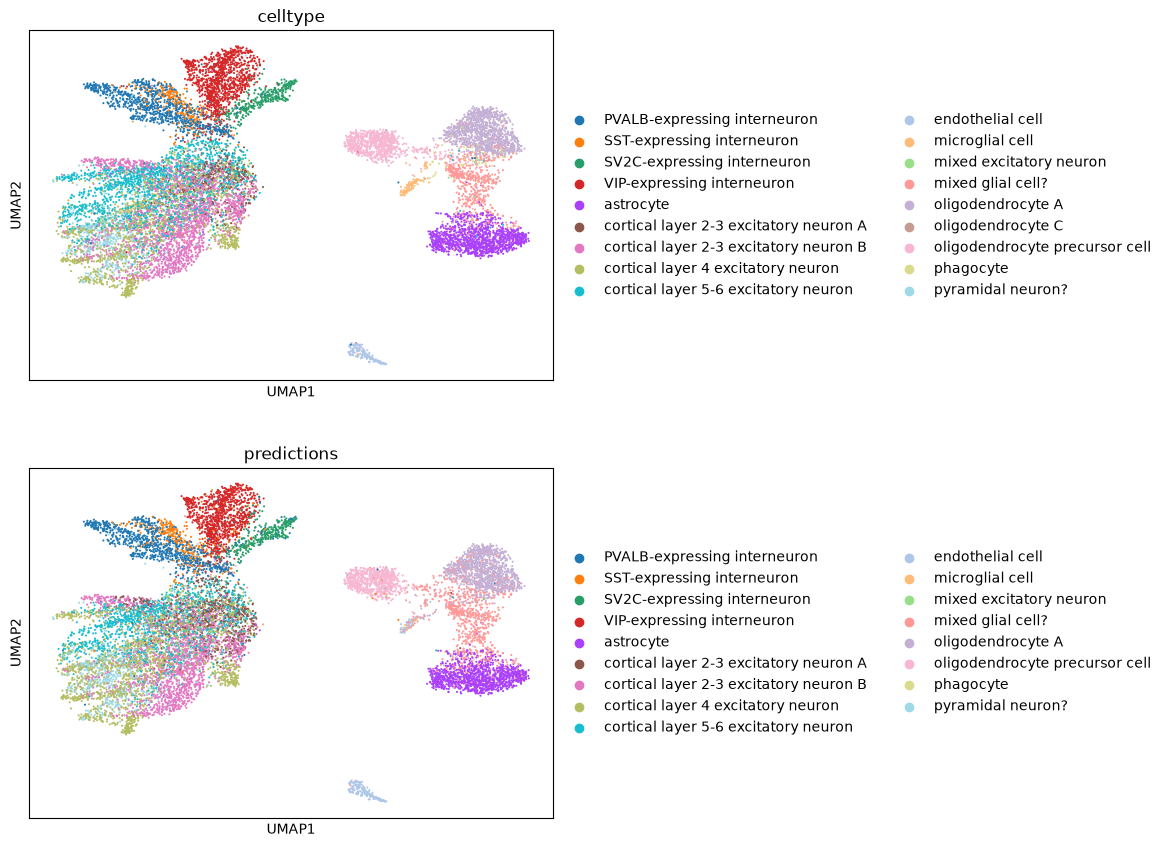

In [9]:
sc.pl.umap(
        adata_test,
        color=[celltype_col, "predictions"],
        ncols=1,
        palette=_palette,
        show=False,
    )
if save: plt.savefig(pred_dir / "results.png", dpi=300, bbox_inches="tight")

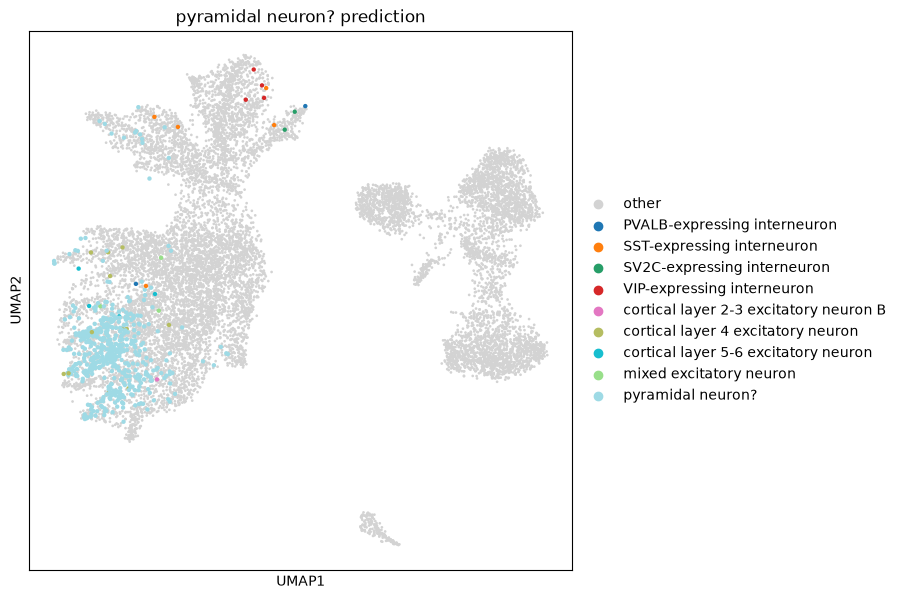

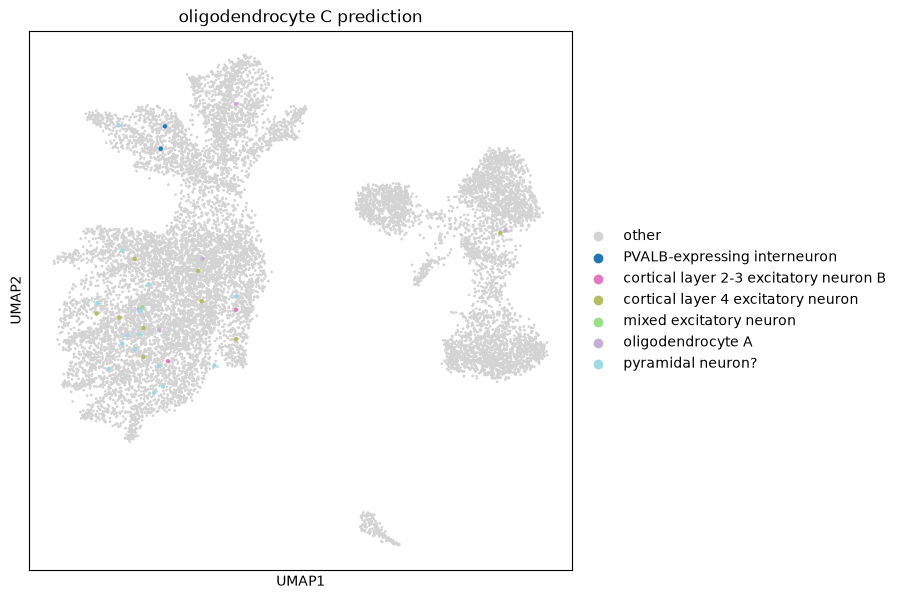

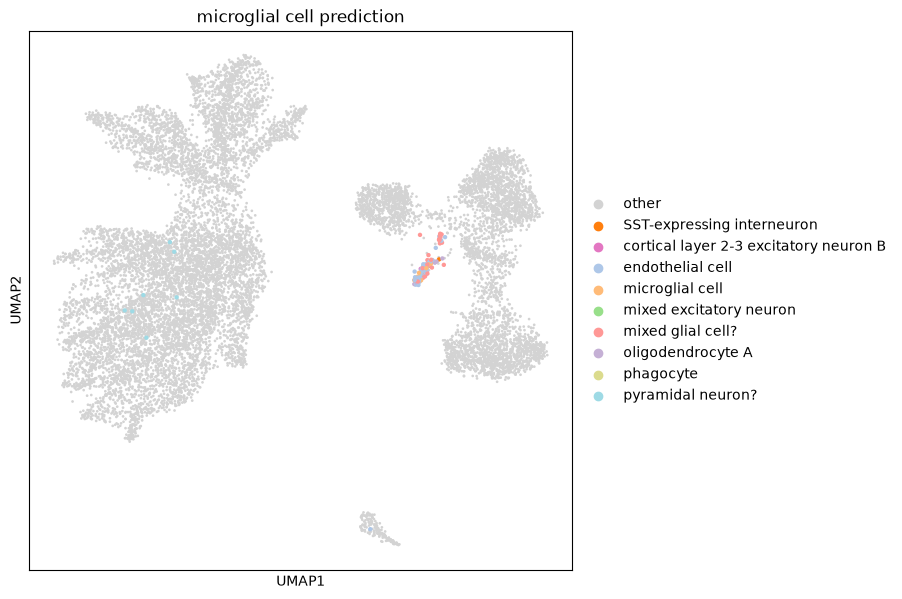

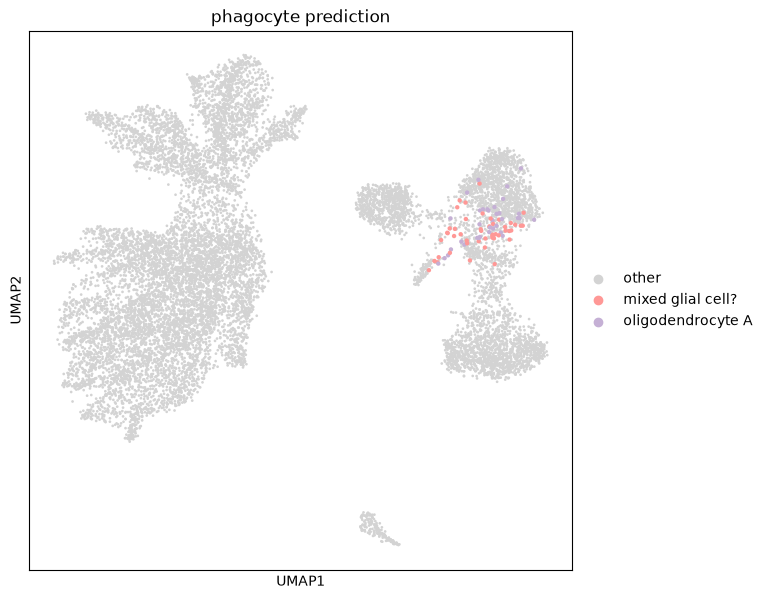

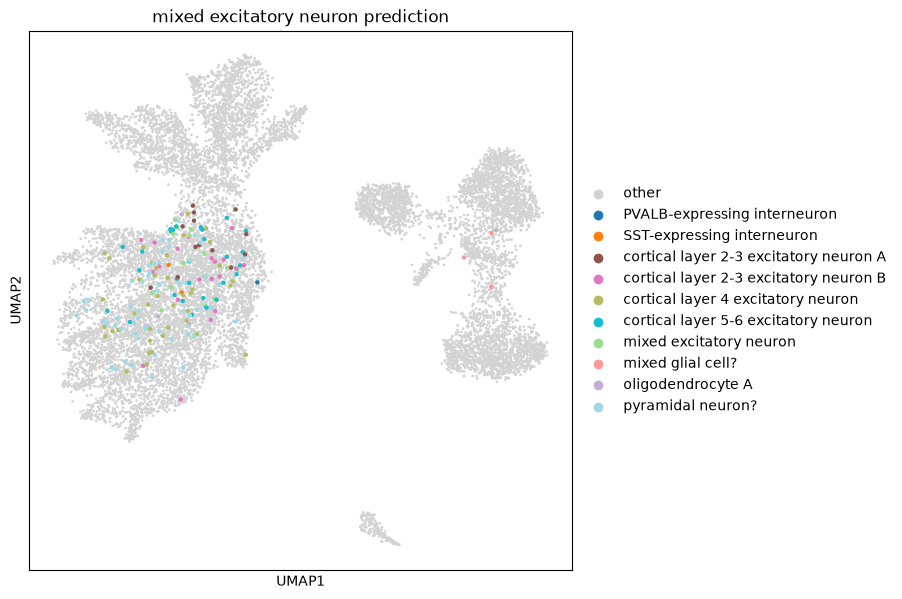

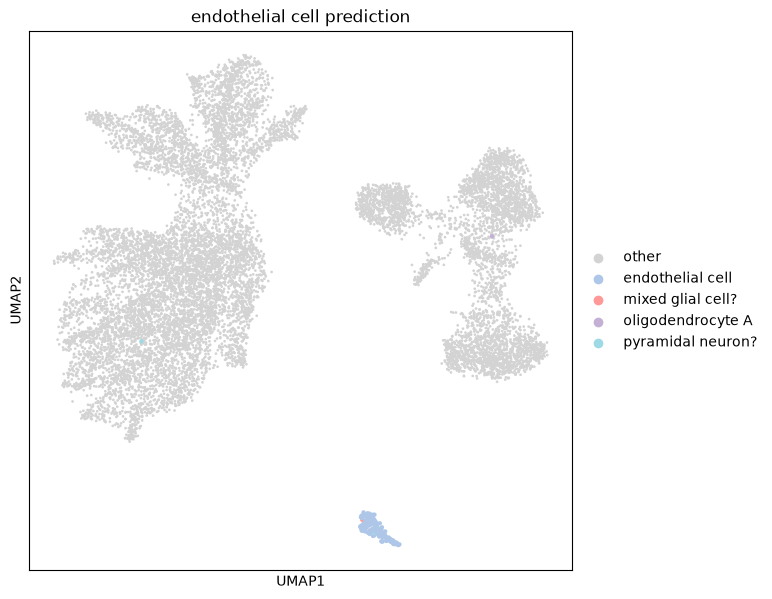

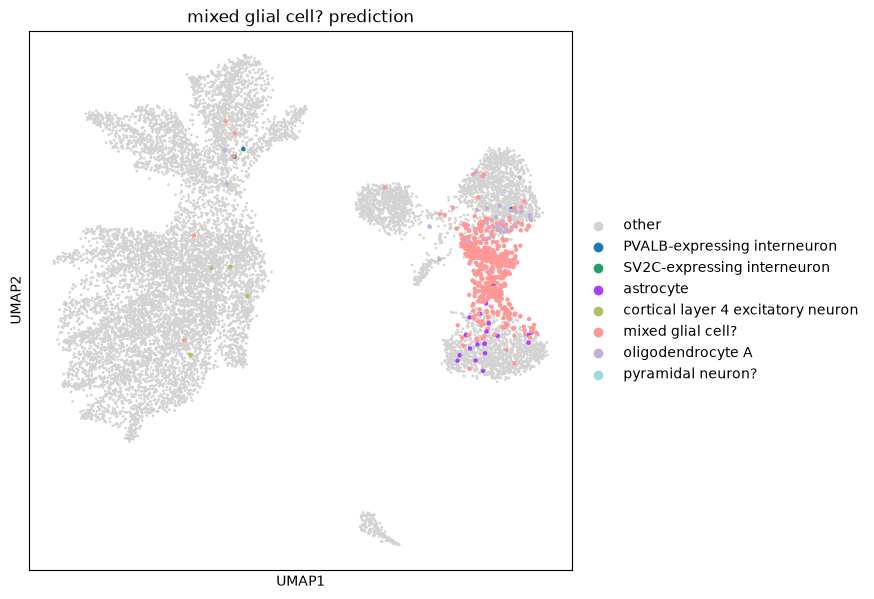

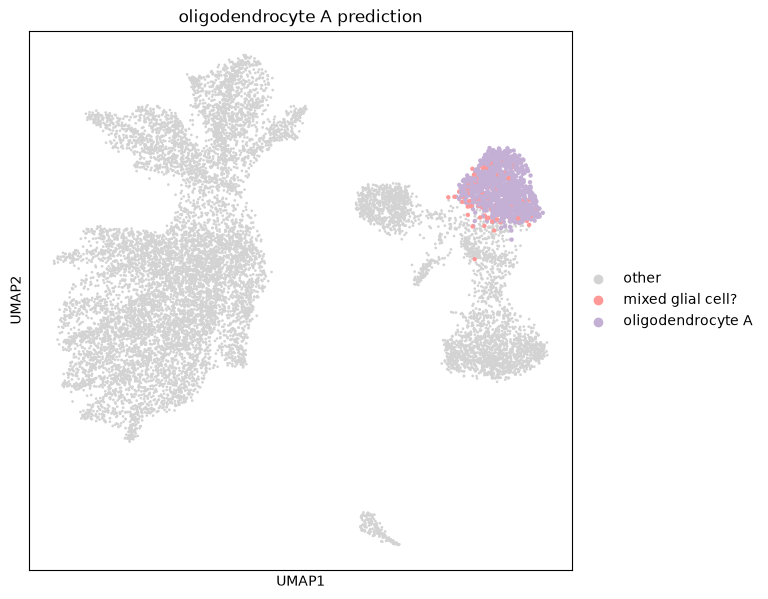

In [10]:
adata_plot = adata_test.copy()
for celltype in ['pyramidal neuron?', 'oligodendrocyte C', 'microglial cell', 'phagocyte', 'mixed excitatory neuron','endothelial cell', 'mixed glial cell?', 'oligodendrocyte A']:
    myutils.inspect_prediction(adata_plot, celltype, palette=_palette, celltype_col="celltype", save_dir=pred_dir)

In [11]:
adata_plot = adata_test.copy()

myutils.inspect_prediction(adata_plot, 'B', palette=_palette, celltype_col="celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'CD4 T', palette=_palette, celltype_col="celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'CD8 T', palette=_palette, celltype_col="celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'CD14+ Monocytes', palette=_palette, celltype_col="celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'FCGR3A+ Monocytes', palette=_palette, celltype_col="celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'Megakaryocytes', palette=_palette, celltype_col="celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'NK', palette=_palette, celltype_col="celltype", save_dir=pred_dir)

In [12]:
adata_plot = adata_test.copy()

myutils.inspect_prediction(adata_plot, 'Lymphoid cells', palette=_palette, celltype_col="consensus_celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'Fibroblasts/Pericytes', palette=_palette, celltype_col="consensus_celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'B/Plasma cells', palette=_palette, celltype_col="consensus_celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'Myeloid cells', palette=_palette, celltype_col="consensus_celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'Endothelial cells', palette=_palette, celltype_col="consensus_celltype", save_dir=pred_dir)
myutils.inspect_prediction(adata_plot, 'Tumor', palette=_palette, celltype_col="consensus_celltype", save_dir=pred_dir)

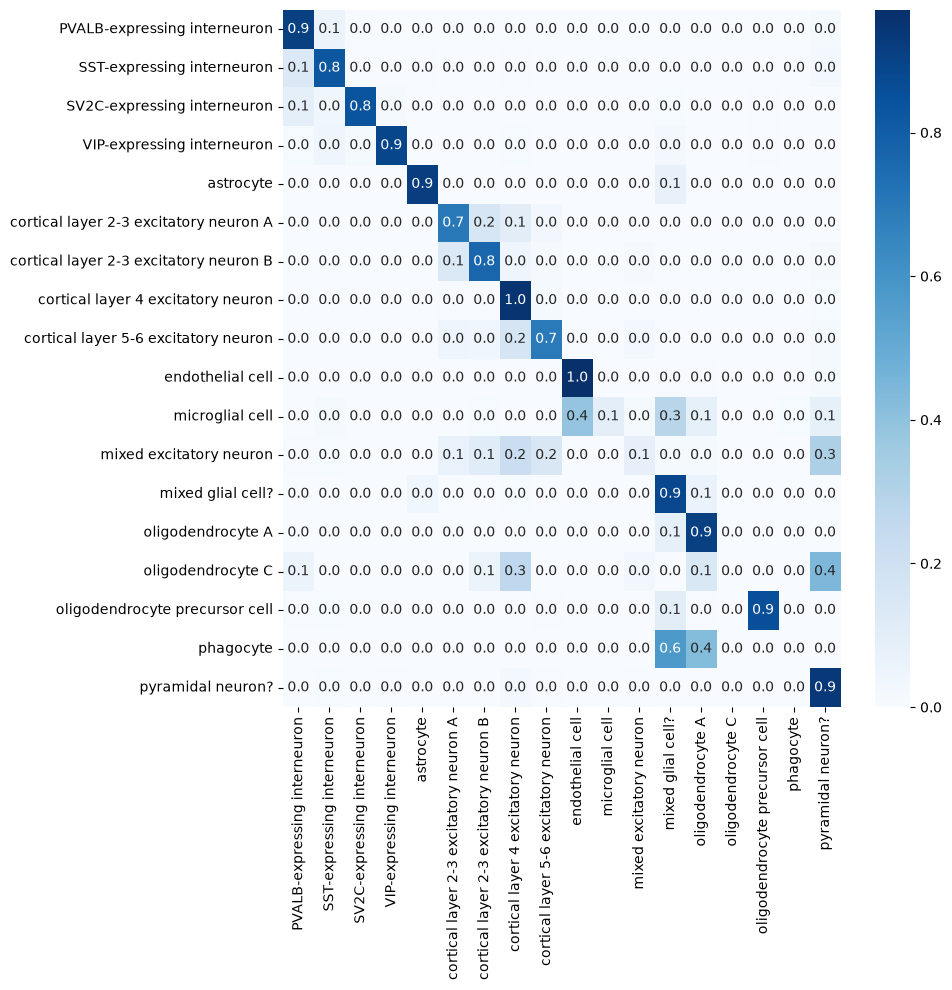

In [14]:
celltypes = adata.obs[celltype_col].unique()
celltypes = [id2type[i] for i in range(len(celltypes))]
for i in {id2type[p] for p in predictions}:
    if i not in celltypes:
        celltypes.remove(i)
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])

decimel = ".1f" if dataset == 'ms' else ".2f"
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=decimel, cmap="Blues")
plt.yticks(rotation=0)
plt.tight_layout()
if save: plt.savefig(pred_dir / "confusion_matrix.png", dpi=300, )

In [5]:
import os

data_dir = experiment/"scGPT/data/ms"
data_file = workspace / "data/ms/filtered_ms_adata.h5ad"
result_dir = experiment/ 'results/pred-with-fine-tuning'


for run in os.listdir(result_dir):
    match = re.match(r'pred_(.+?)-(.+)_.*',run)
    dataset = match.group(1)
    pred_dir = result_dir / run
    result_file = pred_dir / 'results.pkl'
    if not pred_dir.exists(): continue
    if not result_file.exists(): continue
    print(run)

    if (dataset == "pbmc3k"):
        data_file = data_dir = experiment/ "data/pbmc3k_scanpy_annotated_batches.h5ad"
        celltype_col = "celltype"
    if (dataset == "ms"):
        data_file = workspace / "data/ms/filtered_ms_adata.h5ad"
        celltype_col = "celltype"
    if (dataset == "heroes"):
        data_file = experiment / "data/hereos_pool7_scRNA_batches_hvg.h5ad"
        celltype_col = "consensus_celltype"

    with open(result_file, 'rb') as f:
        results = pickle.load(f)
    id2type = results['id_maps']
    predictions = results['predictions']
    labels = results['labels']
    adata_run = sc.read(data_file)
    adata_run = adata_run[adata_run.obs.str_batch == '1']
    adata_run.obs["predictions"] = [id2type[p] for p in predictions]

    sc.pl.umap(
            adata_run,
            color=celltype_col,
            ncols=1,
            show=False
        )
    _palette = dict(
        zip(
            adata_run.obs[celltype_col].cat.categories,
            adata_run.uns[f"{celltype_col}_colors"],
        )
    )
    plt.close()

    sc.pl.umap(
        adata_run,
        color=[celltype_col, "predictions"],
        ncols=1,
        palette=_palette,
        show=False,
    )
    if save: plt.savefig(pred_dir / "results.png", dpi=300, bbox_inches="tight")
    plt.close()

    celltypes = adata_run.obs[celltype_col].unique()
    for celltype in celltypes:
        myutils.inspect_prediction(adata_run, celltype, palette=_palette, celltype_col="celltype", save_dir=pred_dir, show=False)
        plt.close()
    
    celltypes = [id2type[i] for i in range(len(celltypes))]
    for i in {id2type[p] for p in predictions}:
        if i not in celltypes:
            celltypes.remove(i)
    cm = confusion_matrix(labels, predictions)
    cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])
    if save: cm.to_csv(pred_dir/ 'confusion_matrix.csv')

    decimel = ".1f" if dataset == 'ms' else ".2f"
    plt.figure(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt=decimel, cmap="Blues")
    plt.yticks(rotation=0)
    plt.tight_layout()
    if save: plt.savefig(pred_dir / "confusion_matrix.png", dpi=300, )
    plt.close()


pred_ms-2026-10-14_132744
pred_heroes-2026-10-26_205123
pred_heroes-2026-10-25_202937
pred_pbmc3k-2026-10-21_122719
pred_ms-2026-10-21_121900
pred_pbmc3k-2026-10-13_133425
pred_ms-2026-10-13_133232
pred_pbmc3k-2026-10-13_133655
pred_heroes-2026-10-25_200300
pred_heroes-2026-10-25_172348
pred_ms-2026-10-21_121733
